# Validation and Testing

Experiment notebook for the part counting pipeline. It runs the functions in `functions/` on the labeled images in `images/captured_images/` and compares the predicted count to the true count in `images/labels.xlsx`.

1. Run the pipeline on one image and look at each stage
2. Sweep through settings (binary threshold, kernel size, minimum area) on every labeled image
3. Rank the settings to see which work best and which do not work
4. Look at the images the best setting still gets wrong

`autoreload` is on, so edits to the files in `functions/` are picked up without restarting the kernel.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import pandas as pd

from functions.gray_scale import gray_scale_frame
from functions.binary_thresholding import binary_threshold
from functions.morph_close_open import morph_operation
from functions.counting import count_objects

## Dataset

In [2]:
IMAGE_DIR = Path("images/captured_images")
LABELS_FILE = Path("images/labels.xlsx")

# Row N of labels.xlsx holds the true part count for "image (N).jpg"
true_counts = pd.read_excel(LABELS_FILE, header=None)[0].astype(int).tolist()
image_paths = [IMAGE_DIR / f"image ({number}).jpg" for number in range(1, len(true_counts) + 1)]


def load_image(number):
    path = image_paths[number - 1]
    frame = cv2.imread(str(path))

    if frame is None:
        raise FileNotFoundError(path)

    return frame


print(len(image_paths), "labeled images")

156 labeled images


## 1. Run the pipeline on one image

`run_pipeline` chains the same four functions the live camera script uses. `show_pipeline` runs it on one labeled image and plots every stage.

In [3]:
def run_pipeline(frame, threshold=200, kernel_size=3, min_area=300):
    gray = gray_scale_frame(frame)
    binary = binary_threshold(gray, threshold)
    cleaned = morph_operation(binary, kernel_size)
    count = count_objects(cleaned, min_area)

    return gray, binary, cleaned, count


def show_pipeline(image_number, threshold=200, kernel_size=3, min_area=300):
    frame = load_image(image_number)
    gray, binary, cleaned, count = run_pipeline(frame, threshold, kernel_size, min_area)

    views = [cv2.cvtColor(frame, cv2.COLOR_BGR2RGB), gray, binary, cleaned]
    titles = [
        "Original",
        "Grayscale",
        f"Binary threshold ({threshold})",
        f"Closing + opening ({kernel_size}x{kernel_size} kernel)",
    ]

    fig, ax = plt.subplots(2, 2, figsize=(14, 8))

    for a, view, title in zip(ax.flat, views, titles):
        a.imshow(view, cmap="gray", vmin=0, vmax=255)
        a.set_title(title)
        a.axis("off")

    fig.suptitle(
        f"image ({image_number}).jpg   predicted: {count}   true: {true_counts[image_number - 1]}   "
        f"(min_area={min_area})"
    )
    plt.tight_layout()
    plt.show()

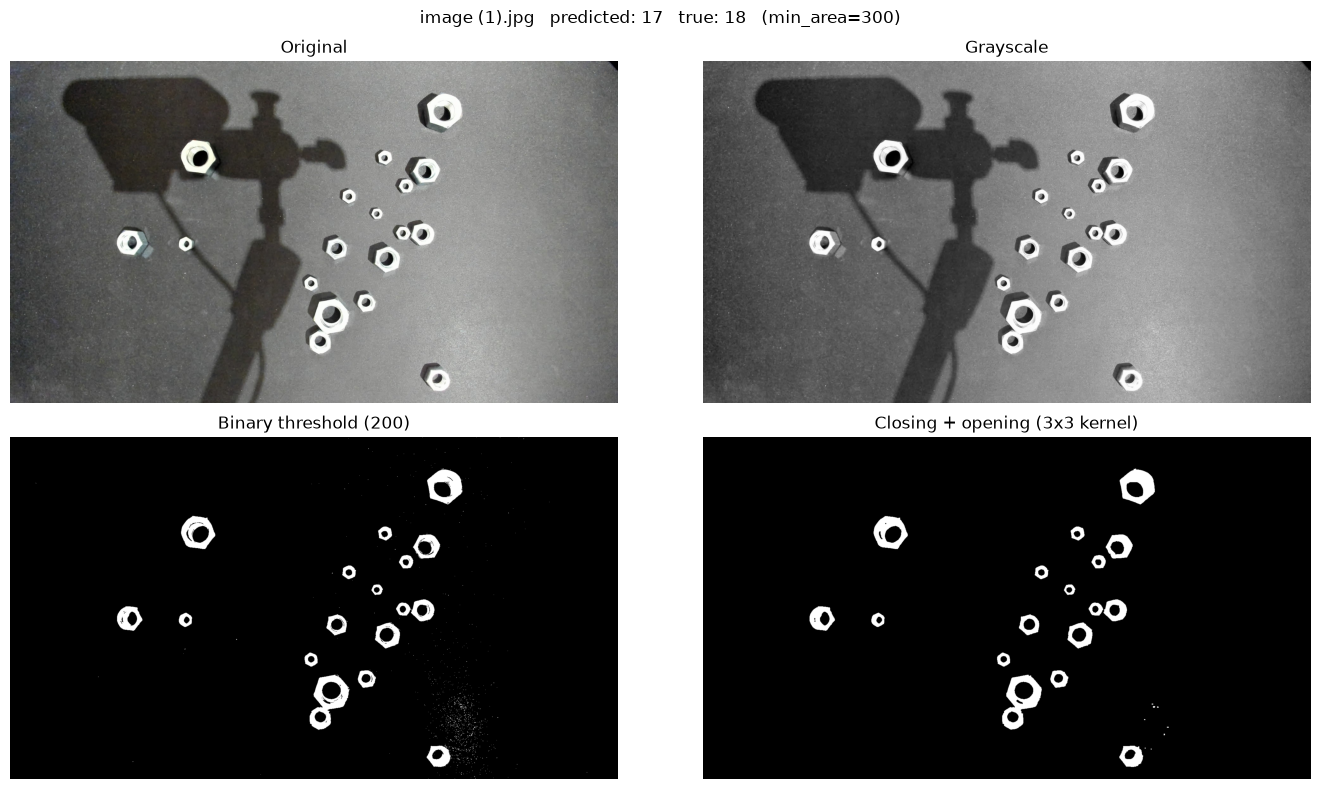

In [4]:
# Change these to try one combination of settings on one image
show_pipeline(image_number=1, threshold=200, kernel_size=3, min_area=300)

## 2. Sweep through settings

Every combination of the values below is run on every labeled image. Edit the lists to try other values. A bigger grid takes longer because each combination runs on all the images.

- `THRESHOLDS`: grayscale value a pixel must be above to become white
- `KERNEL_SIZES`: side length of the square kernel for closing + opening (1 = no morphology)
- `MIN_AREAS`: smallest blob, in pixels, that counts as a part

In [5]:
THRESHOLDS = [140, 160, 180, 200, 220, 240]
KERNEL_SIZES = [1, 3, 5, 7, 9]
MIN_AREAS = [100, 300, 1000, 3000]

rows = []

for number, true_count in enumerate(true_counts, start=1):
    gray = gray_scale_frame(load_image(number))

    for threshold in THRESHOLDS:
        binary = binary_threshold(gray, threshold)

        for kernel_size in KERNEL_SIZES:
            cleaned = morph_operation(binary, kernel_size)

            for min_area in MIN_AREAS:
                rows.append({
                    "image": number,
                    "threshold": threshold,
                    "kernel_size": kernel_size,
                    "min_area": min_area,
                    "true": true_count,
                    "predicted": count_objects(cleaned, min_area),
                })

# One row per image per combination of settings
results = pd.DataFrame(rows)
results["error"] = results["predicted"] - results["true"]

print(len(results), "runs")
results.head()

18720 runs


,image,threshold,kernel_size,min_area,true,predicted,error
0,1,140,1,100,18,38,20
1,1,140,1,300,18,10,-8
2,1,140,1,1000,18,5,-13
3,1,140,1,3000,18,3,-15
4,1,140,3,100,18,37,19


## 3. Which settings work

One row per combination of settings, best first:

- `exact_accuracy`: share of images where the predicted count equals the true count
- `mean_abs_error`: how many parts the count is off by on average
- `mean_error`: positive means it overcounts, negative means it undercounts

In [6]:
SETTINGS = ["threshold", "kernel_size", "min_area"]

summary = (
    results.assign(exact=results["error"] == 0, abs_error=results["error"].abs())
    .groupby(SETTINGS)
    .agg(
        exact_accuracy=("exact", "mean"),
        mean_abs_error=("abs_error", "mean"),
        mean_error=("error", "mean"),
    )
    .reset_index()
    .sort_values(["exact_accuracy", "mean_abs_error"], ascending=[False, True])
    .reset_index(drop=True)
)

best_threshold, best_kernel_size, best_min_area = summary.loc[0, SETTINGS].tolist()

print(f"Best: threshold={best_threshold}, kernel_size={best_kernel_size}, min_area={best_min_area}")
print("Top 10 settings")
summary.head(10)

Best: threshold=200, kernel_size=1, min_area=300
Top 10 settings


,threshold,kernel_size,min_area,exact_accuracy,mean_abs_error,mean_error
0,200,1,300,0.775641,0.262821,-0.070513
1,200,1,100,0.724359,0.365385,0.032051
2,200,1,1000,0.698718,0.378205,-0.365385
3,220,5,300,0.698718,0.423077,-0.230769
4,200,3,1000,0.685897,0.532051,-0.532051
5,200,5,1000,0.679487,0.557692,-0.557692
6,200,7,1000,0.673077,0.564103,-0.551282
7,220,5,1000,0.647436,0.544872,-0.544872
8,200,3,300,0.647436,0.551282,-0.166667
9,220,3,1000,0.641026,0.519231,-0.493590


In [7]:
print("Bottom 10 settings")
summary.tail(10)

Bottom 10 settings


,threshold,kernel_size,min_area,exact_accuracy,mean_abs_error,mean_error
110,140,9,100,0.019231,8.153846,8.051282
111,140,7,100,0.012821,11.192308,11.179487
112,160,7,100,0.012821,22.615385,22.615385
113,140,5,100,0.000000,16.217949,16.217949
114,160,9,100,0.000000,17.205128,17.192308
115,140,3,100,0.000000,19.948718,19.948718
116,140,1,100,0.000000,20.307692,20.307692
117,160,1,100,0.000000,21.006410,21.006410
118,160,3,100,0.000000,25.044872,25.044872
119,160,5,100,0.000000,26.782051,26.782051


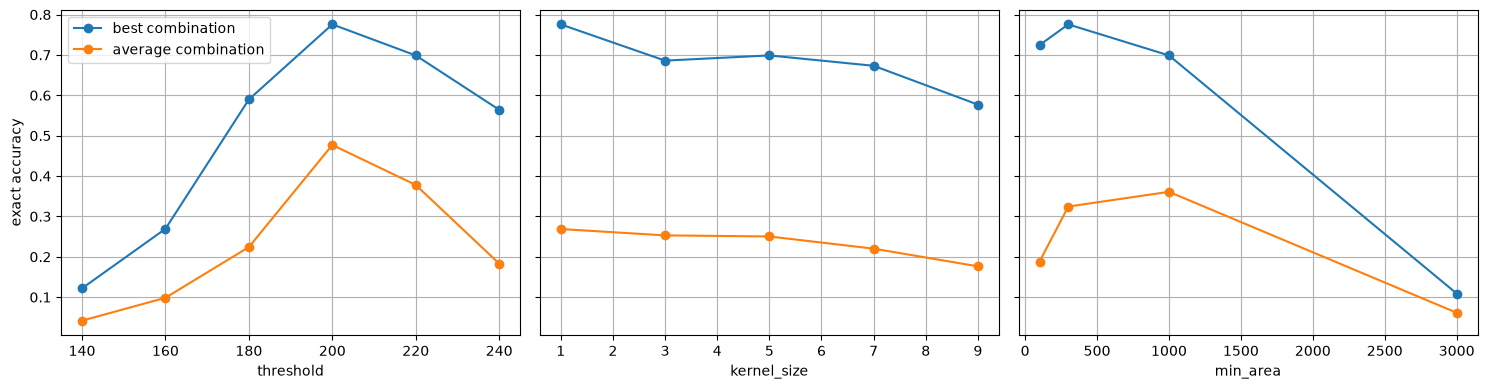

In [8]:
# Effect of each setting on its own: the best and the average accuracy
# over all combinations that use that value
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, setting in zip(axes, SETTINGS):
    best_by_value = summary.groupby(setting)["exact_accuracy"].max()
    mean_by_value = summary.groupby(setting)["exact_accuracy"].mean()

    ax.plot(best_by_value.index, best_by_value.values, marker="o", label="best combination")
    ax.plot(mean_by_value.index, mean_by_value.values, marker="o", label="average combination")
    ax.set_xlabel(setting)
    ax.grid(True)

axes[0].set_ylabel("exact accuracy")
axes[0].legend()
plt.tight_layout()
plt.show()

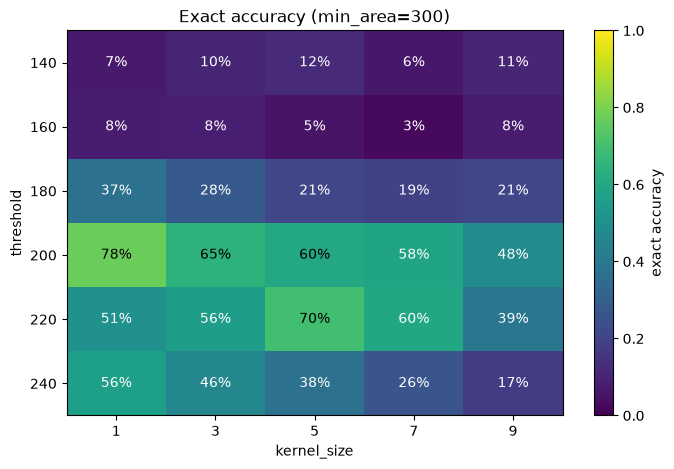

In [9]:
# Threshold against kernel size, with min_area fixed at its best value
grid = summary[summary["min_area"] == best_min_area].pivot(
    index="threshold", columns="kernel_size", values="exact_accuracy"
)

fig, ax = plt.subplots(figsize=(8, 5))
heatmap = ax.imshow(grid.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")

ax.set_xticks(range(len(grid.columns)), labels=grid.columns)
ax.set_yticks(range(len(grid.index)), labels=grid.index)
ax.set_xlabel("kernel_size")
ax.set_ylabel("threshold")
ax.set_title(f"Exact accuracy (min_area={best_min_area})")

for row in range(grid.shape[0]):
    for col in range(grid.shape[1]):
        value = grid.values[row, col]
        ax.text(col, row, f"{value:.0%}", ha="center", va="center",
                color="black" if value > 0.6 else "white")

fig.colorbar(heatmap, label="exact accuracy")
plt.show()

## 4. Where the best setting still fails

The images the best combination counts wrong, largest error first.

In [10]:
best_results = results[
    (results["threshold"] == best_threshold)
    & (results["kernel_size"] == best_kernel_size)
    & (results["min_area"] == best_min_area)
]

wrong = best_results[best_results["error"] != 0].sort_values("error", key=abs, ascending=False)

print(f"{len(wrong)} of {len(best_results)} images counted wrong")
wrong[["image", "true", "predicted", "error"]]

35 of 156 images counted wrong


,image,true,predicted,error
8341,70,15,12,-3
3181,27,15,13,-2
15181,127,18,20,2
18661,156,0,2,2
3301,28,15,13,-2
61,1,18,17,-1
181,2,12,11,-1
421,4,9,8,-1
1381,12,8,7,-1
541,5,10,9,-1


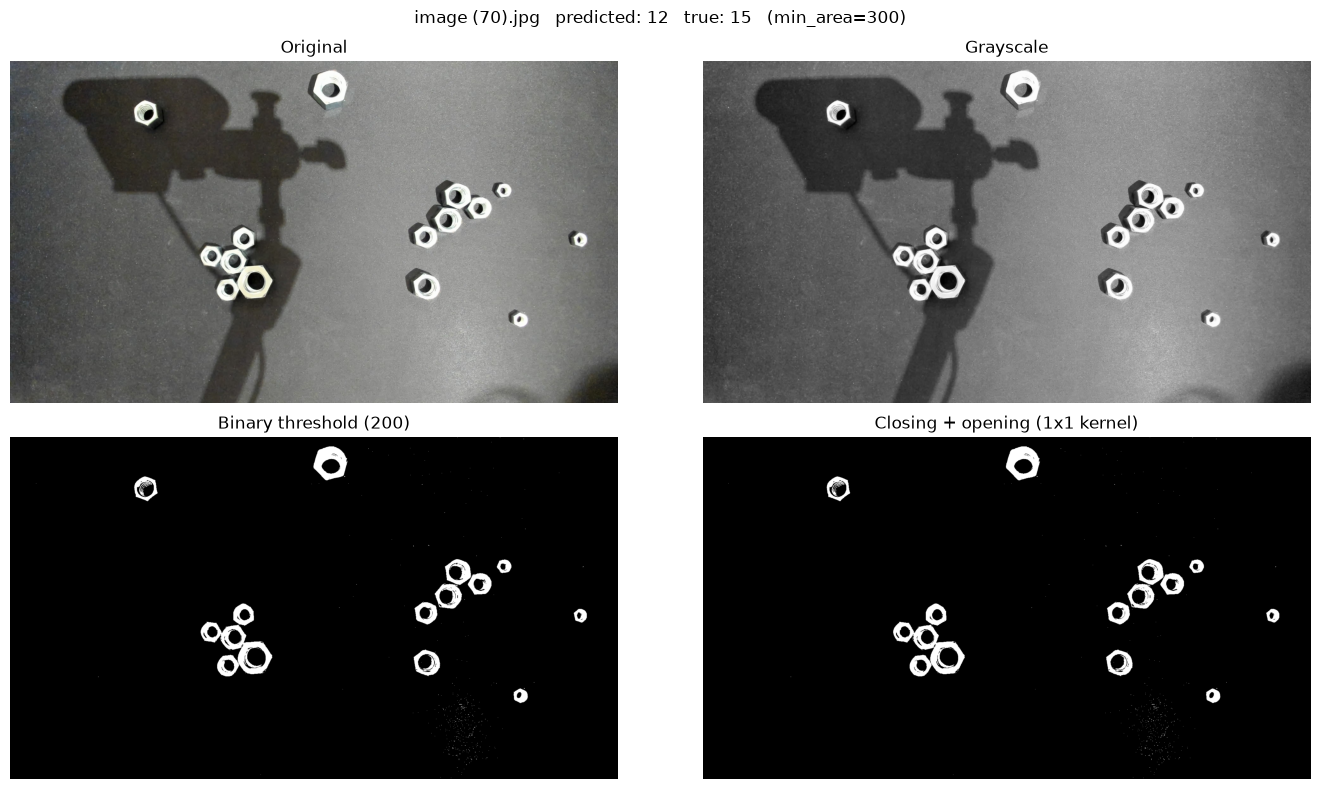

In [11]:
# Look at the worst miss stage by stage (set image_number yourself to inspect any other image)
if len(wrong) > 0:
    show_pipeline(
        image_number=int(wrong.iloc[0]["image"]),
        threshold=best_threshold,
        kernel_size=best_kernel_size,
        min_area=best_min_area,
    )